# Masked Autoregressive Flow (MAF) Implementation

This notebook implements a Masked Autoregressive Flow model as specified in the assignment.

## Specifications:
- **Image dimensions**: 128 × 128 × 3
- **Architecture**: MADE (Masked Autoencoder for Distribution Estimation)
- **Transformation blocks**: 7
- **Batch size**: 8
- **MADE layers**:
  - Linear(input: 128×128×3, output: 512) - masked
  - Linear(input: 512, output: 512) - masked
  - Linear(input: 512, output: 2×128×128×3) - masked

**Important**: The Linear layers are not regular linear layers and must maintain the autoregressive condition.


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributions as dist
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time
import os
import tarfile
import urllib.request

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


## Configuration


In [2]:
# Configuration
IMG_SIZE = 64
CHANNELS = 3
INPUT_DIM = IMG_SIZE * IMG_SIZE * CHANNELS  # 64 * 64 * 3 = 12288

HIDDEN_DIM = 1024
NUM_BLOCKS = 7
BATCH_SIZE = 8

print(f"Input dimension: {INPUT_DIM}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Number of blocks: {NUM_BLOCKS}")
print(f"Batch size: {BATCH_SIZE}")


Input dimension: 12288
Hidden dimension: 1024
Number of blocks: 7
Batch size: 8


## Implementation

### Masked Linear Layer
The MaskedLinear layer ensures autoregressive property by masking connections.


In [3]:
class MaskedLinear(nn.Linear):
    """
    Masked linear layer that enforces autoregressive property.
    The mask ensures that each output dimension only depends on previous input dimensions.
    Inherits from nn.Linear to get weight and bias parameters.
    """
    def __init__(self, in_features, out_features, bias=True):
        super().__init__(in_features, out_features, bias)
        # Register mask as buffer (not a parameter, but part of state)
        self.register_buffer('mask', torch.ones(out_features, in_features))

    def set_mask(self, mask):
        """Set the mask matrix"""
        self.mask.data.copy_(mask)

    def forward(self, x):
        # Apply mask to weight matrix before linear transformation
        return F.linear(x, self.weight * self.mask, self.bias)


### MADE (Masked Autoencoder for Distribution Estimation)
MADE layer that implements the autoregressive transformation with masked connections.


In [4]:
def create_masks(input_dim, hidden_dim, output_dim):
    """
    Create masks for MADE architecture to ensure autoregressive property.

    Args:
        input_dim: Input dimension (D)
        hidden_dim: Hidden layer dimension (H)
        output_dim: Output dimension (must be 2 * input_dim)

    Returns:
        Tuple of masks (mask1, mask2, mask3) for three layers
    """
    assert output_dim == 2 * input_dim, "output_dim must be 2 * input_dim"

    # Assign degrees to input: [1, 2, ..., D]
    input_degrees = torch.arange(1, input_dim + 1, dtype=torch.float32)

    # Random degrees for hidden units: [1, ..., D-1]
    hidden_degrees = torch.randint(1, input_dim, (hidden_dim,), dtype=torch.float32)

    # Output degrees: [1,1,2,2,...,D,D]
    output_degrees = torch.repeat_interleave(input_degrees, 2)

    # Create masks
    # Layer 1: hidden ← input
    mask1 = (hidden_degrees.unsqueeze(-1) >= input_degrees.unsqueeze(0)).float()

    # Layer 2: hidden ← hidden (with same degrees)
    mask2 = (hidden_degrees.unsqueeze(-1) >= hidden_degrees.unsqueeze(0)).float()

    # Layer 3: output ← hidden
    mask3 = (output_degrees.unsqueeze(-1) >= hidden_degrees.unsqueeze(0)).float()

    return mask1, mask2, mask3


class MADE(nn.Module):
    """
    MADE (Masked Autoencoder for Distribution Estimation) network.
    Implements the architecture:
    - Linear(input: 128*128*3, output: 512) - masked
    - Linear(input: 512, output: 512) - masked
    - Linear(input: 512, output: 2*128*128*3) - masked
    """
    def __init__(self, input_dim, hidden_dim, output_dim=None):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        if output_dim is None:
            output_dim = 2 * input_dim  # mean and log_scale for each dimension
        self.output_dim = output_dim

        # Create masked linear layers
        self.fc1 = MaskedLinear(input_dim, hidden_dim)
        self.fc2 = MaskedLinear(hidden_dim, hidden_dim)
        self.fc3 = MaskedLinear(hidden_dim, output_dim)

        # Activation function
        self.activation = nn.ReLU()

        # Initialize masks
        self.reset_masks()

    def reset_masks(self):
        """Initialize and set masks for all layers"""
        mask1, mask2, mask3 = create_masks(self.input_dim, self.hidden_dim, self.output_dim)
        self.fc1.set_mask(mask1)
        self.fc2.set_mask(mask2)
        self.fc3.set_mask(mask3)

    def forward(self, x):
        """
        Forward pass through MADE network.

        Args:
            x: Input tensor of shape (batch_size, input_dim)

        Returns:
            Output tensor of shape (batch_size, output_dim)
            where output_dim = 2 * input_dim (mean and log_scale)
        """
        h = self.activation(self.fc1(x))
        h = self.activation(self.fc2(h))
        return self.fc3(h)


In [5]:
class MAFBlock(nn.Module):
    """
    A single transformation block in Masked Autoregressive Flow.
    Each block applies an affine transformation parameterized by MADE.
    """
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.made = MADE(input_dim, hidden_dim, output_dim=2 * input_dim)
        # Clamp log_scale to prevent numerical instability
        self.log_scale_bounds = (-5.0, 5.0)

    def forward(self, x, log_det):
        """
        Forward transformation: x -> z

        Args:
            x: Input tensor (batch_size, input_dim)
            log_det: Current log determinant (batch_size,)

        Returns:
            z: Transformed tensor (batch_size, input_dim)
            log_det: Updated log determinant (batch_size,)
        """
        # Get shift and log_scale from MADE
        out = self.made(x)
        shift, log_scale = out.chunk(2, dim=-1)

        # Clamp log_scale for numerical stability
        log_scale = torch.clamp(log_scale, *self.log_scale_bounds)

        # Affine transformation: z = (x - shift) * exp(-log_scale)
        z = (x - shift) * torch.exp(-log_scale)

        # Update log determinant: log|det| = log|det| - sum(log_scale)
        log_det = log_det - log_scale.sum(dim=-1)

        return z, log_det

    def inverse(self, z):
        """
        Inverse transformation: z -> x (used for sampling)
        This is sequential because of autoregressive property.

        Args:
            z: Latent tensor (batch_size, input_dim)

        Returns:
            x: Reconstructed tensor (batch_size, input_dim)
        """
        batch_size, input_dim = z.shape
        x = torch.zeros_like(z)

        # Sequential generation: each dimension depends on previous ones
        for d in range(input_dim):
            out = self.made(x)
            shift, log_scale = out.chunk(2, dim=-1)
            log_scale = torch.clamp(log_scale, *self.log_scale_bounds)

            # Inverse affine transformation: x = z * exp(log_scale) + shift
            x[:, d] = z[:, d] * torch.exp(log_scale[:, d]) + shift[:, d]

        return x


In [6]:
class MaskedAutoregressiveFlow(nn.Module):
    """
    Masked Autoregressive Flow model.
    Composed of multiple MAF blocks (7 blocks as specified).
    """
    def __init__(self, input_dim, hidden_dim, num_blocks):
        super().__init__()
        self.input_dim = input_dim
        self.num_blocks = num_blocks

        # Create transformation blocks
        self.blocks = nn.ModuleList([
            MAFBlock(input_dim, hidden_dim) for _ in range(num_blocks)
        ])

    def _get_base_dist(self):
        """Get base distribution on the correct device"""
        device = next(self.parameters()).device
        return dist.Normal(
            torch.zeros(self.input_dim, device=device),
            torch.ones(self.input_dim, device=device)
        )

    def forward(self, x):
        """
        Forward pass: transform x to z and compute log probability.

        Args:
            x: Input tensor (batch_size, input_dim)

        Returns:
            z: Latent tensor (batch_size, input_dim)
            log_prob: Log probability (batch_size,)
        """
        z = x
        log_det = torch.zeros(x.size(0), device=x.device)

        # Apply all transformation blocks
        for block in self.blocks:
            z, log_det = block(z, log_det)

        # Compute log probability: log p(x) = log p(z) + log|det|
        base_dist = self._get_base_dist()
        log_prob_base = base_dist.log_prob(z).sum(dim=-1)
        log_prob = log_prob_base + log_det

        return z, log_prob

    def sample(self, n_samples):
        """
        Generate samples by inverse transformation.

        Args:
            n_samples: Number of samples to generate

        Returns:
            samples: Generated samples (n_samples, input_dim)
        """
        # Sample from base distribution
        base_dist = self._get_base_dist()
        z = base_dist.sample((n_samples,))

        # Apply inverse transformations in reverse order
        x = z
        for block in reversed(self.blocks):
            x = block.inverse(x)

        return x


## Model Initialization


In [7]:
# Create model
model = MaskedAutoregressiveFlow(INPUT_DIM, HIDDEN_DIM, NUM_BLOCKS).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model created successfully!")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model size: {total_params / 1e6:.2f}M parameters")


Model created successfully!
Total parameters: 271,767,552
Trainable parameters: 271,767,552
Model size: 271.77M parameters


## Training Setup

To train the model, you would need:
1. A dataset of 128×128×3 images
2. DataLoader with batch_size=8
3. Optimizer (e.g., Adam)
4. Training loop that minimizes negative log-likelihood

Example training code structure:
```python
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(num_epochs):
    for batch in dataloader:
        # Flatten images: (batch, 3, 128, 128) -> (batch, 49152)
        x = batch.view(batch.size(0), -1).to(device)
        
        # Forward pass
        _, log_prob = model(x)
        loss = -log_prob.mean()  # Negative log-likelihood
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
```


## Dataset Loading

Download and load the MVTec AD capsule dataset for training.


In [8]:
class MVTecDataset(Dataset):
    """Dataset class for MVTec AD capsule images"""
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []

        # Collect all image paths from train/good directory
        train_dir = os.path.join(root_dir, 'train', 'good')
        if os.path.exists(train_dir):
            for filename in os.listdir(train_dir):
                if filename.endswith(('.png', '.jpg', '.jpeg')):
                    self.image_paths.append(os.path.join(train_dir, filename))

        print(f"Found {len(self.image_paths)} images in dataset")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image

import kagglehub
import os

def download_dataset():
    """
    Download the MVTec AD dataset using kagglehub.
    Returns the path to the 'capsule' subdirectory within the downloaded dataset.
    """
    print("Downloading MVTec AD dataset via kagglehub...")

    # Download the full MVTec AD dataset from Kaggle
    dataset_root = kagglehub.dataset_download("ipythonx/mvtec-ad")

    # Construct path to the 'capsule' folder
    capsule_dir = os.path.join(dataset_root, "capsule")

    # Verify the capsule directory exists
    if not os.path.exists(capsule_dir):
        raise FileNotFoundError(f"'capsule' folder not found at {capsule_dir}. "
                              f"Please check the dataset structure on Kaggle.")

    print(f"Dataset downloaded successfully.")
    print(f"Root: {dataset_root}")
    print(f"Capsule directory: {capsule_dir}")

    return capsule_dir

# Use the function
dataset_dir = download_dataset()


Using Colab cache for faster access to the 'mvtec-ad' dataset.
Dataset downloaded successfully.
Root: /kaggle/input/mvtec-ad
Capsule directory: /kaggle/input/mvtec-ad/capsule


In [9]:
# Define transforms: resize to 128x128 and convert to tensor
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    # Normalize to [0, 1] range (already done by ToTensor)
])

# Create dataset and dataloader
dataset = MVTecDataset(dataset_dir, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

print(f"Dataset size: {len(dataset)}")
print(f"Number of batches: {len(dataloader)}")


Found 219 images in dataset
Dataset size: 219
Number of batches: 28


## Model Training

Train the MAF model on the MVTec AD capsule dataset and measure training time.


In [10]:
# Reinitialize model for training
model = MaskedAutoregressiveFlow(INPUT_DIM, HIDDEN_DIM, NUM_BLOCKS).to(device)

# Setup optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Training parameters
NUM_EPOCHS = 150  # Adjust based on your needs

# Training loop with timing
model.train()
training_start_time = time.time()

print("Starting training...")
print(f"Number of epochs: {NUM_EPOCHS}")
print(f"Number of batches per epoch: {len(dataloader)}")

for epoch in range(NUM_EPOCHS):
    epoch_losses = []

    for batch_idx, images in enumerate(tqdm(dataloader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")):
        # Flatten images: (batch, 3, 128, 128) -> (batch, 49152)
        x = images.view(images.size(0), -1).to(device)

        # Forward pass
        _, log_prob = model(x)
        loss = -log_prob.mean()  # Negative log-likelihood

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    avg_loss = np.mean(epoch_losses)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - Average Loss: {avg_loss:.4f}")

training_end_time = time.time()
training_time = training_end_time - training_start_time

print(f"\n✓ Training completed!")
print(f"Total training time: {training_time:.2f} seconds ({training_time/60:.2f} minutes)")


Starting training...
Number of epochs: 150
Number of batches per epoch: 28


Epoch 1/150: 100%|██████████| 28/28 [00:15<00:00,  1.80it/s]


Epoch 1/150 - Average Loss: 5680.5666


Epoch 2/150: 100%|██████████| 28/28 [00:14<00:00,  1.94it/s]


Epoch 2/150 - Average Loss: -11536.5883


...

Epoch 148/150 - Average Loss: -46368.7224


Epoch 149/150: 100%|██████████| 28/28 [00:14<00:00,  1.90it/s]


Epoch 149/150 - Average Loss: -46489.5532


Epoch 150/150: 100%|██████████| 28/28 [00:14<00:00,  1.95it/s]

Epoch 150/150 - Average Loss: -46233.3050

✓ Training completed!
Total training time: 2175.89 seconds (36.26 minutes)


## Image Generation

Generate 5 images using the trained model. Image generation in autoregressive models is time-consuming, so we use tqdm to monitor progress.


now


In [19]:
# Set model to evaluation mode
model.eval()

# Generate 5 images
NUM_GENERATE = 5
print(f"Generating {NUM_GENERATE} images...")
print("Note: Image generation in autoregressive models is time-consuming due to sequential processing.")

generation_start_time = time.time()

with torch.no_grad():
    # Generate samples with progress bar
    generated_samples = []
    for i in tqdm(range(NUM_GENERATE), desc="Generating images"):
        sample = model.sample(1)  # Generate one image at a time
        generated_samples.append(sample.cpu())

# Stack all samples
generated_images = torch.cat(generated_samples, dim=0)

generation_end_time = time.time()
generation_time = generation_end_time - generation_start_time

print(f"\n✓ Image generation completed!")
print(f"Total generation time: {generation_time:.2f} seconds ({generation_time/60:.2f} minutes)")
print(f"Average time per image: {generation_time/NUM_GENERATE:.2f} seconds")


Generating 5 images...
Note: Image generation in autoregressive models is time-consuming due to sequential processing.


Generating images: 100%|██████████| 5/5 [18:20<00:00, 220.20s/it]


✓ Image generation completed!
Total generation time: 1100.99 seconds (18.35 minutes)
Average time per image: 220.20 seconds


maf_


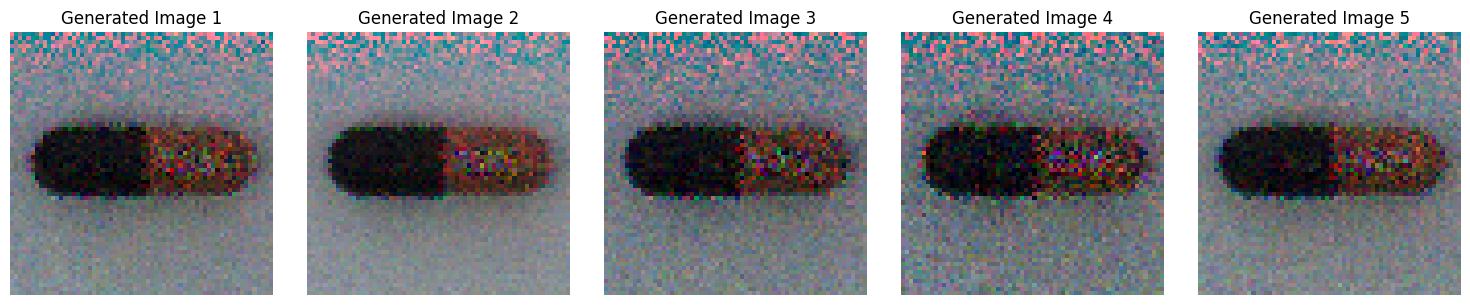

Generated images saved as 'generated_images.png'


In [20]:
# generated_images: (N, D) raw output from inverse flow (in ℝ)

# Reshape: (batch, 49152) -> (batch, 3, IMG_SIZE, IMG_SIZE)
generated_images_reshaped = generated_images.view(NUM_GENERATE, CHANNELS, IMG_SIZE, IMG_SIZE)

# Clamp to [0,1] (not strictly needed after sigmoid, but safe)
generated_images_reshaped = torch.clamp(generated_images_reshaped, 0, 1)

# Convert to numpy for visualization
generated_images_np = generated_images_reshaped.permute(0, 2, 3, 1).cpu().numpy()

# Display
fig, axes = plt.subplots(1, NUM_GENERATE, figsize=(15, 3))
if NUM_GENERATE == 1:
    axes = [axes]

for i in range(NUM_GENERATE):
    axes[i].imshow(generated_images_np[i])
    axes[i].set_title(f'Generated Image {i+1}')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('generated_images.png', dpi=150, bbox_inches='tight')
plt.show()

print("Generated images saved as 'generated_images.png'")


## Time Comparison

Compare training time with image generation time.


TIME COMPARISON
Training time:        2175.89 seconds (36.26 minutes)
Generation time:      1100.99 seconds (18.35 minutes)
Generation time for 5 images: 1100.99 seconds
Average time per image: 220.20 seconds

Ratio (Generation/Training): 0.51x


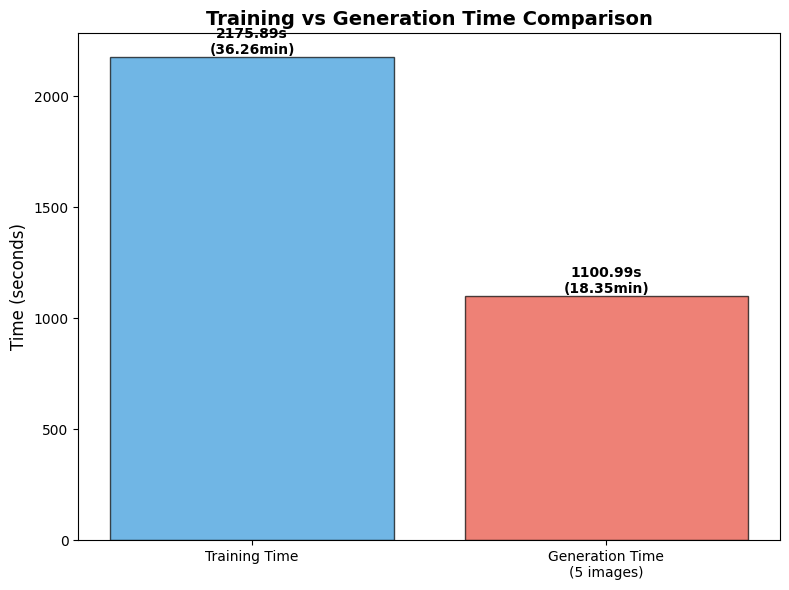


Time comparison chart saved as 'time_comparison.png'


In [21]:
# Time comparison
print("=" * 60)
print("TIME COMPARISON")
print("=" * 60)
print(f"Training time:        {training_time:.2f} seconds ({training_time/60:.2f} minutes)")
print(f"Generation time:      {generation_time:.2f} seconds ({generation_time/60:.2f} minutes)")
print(f"Generation time for {NUM_GENERATE} images: {generation_time:.2f} seconds")
print(f"Average time per image: {generation_time/NUM_GENERATE:.2f} seconds")
print()
print(f"Ratio (Generation/Training): {generation_time/training_time:.2f}x")
print("=" * 60)

# Create a bar chart comparison
fig, ax = plt.subplots(figsize=(8, 6))
times = [training_time, generation_time]
labels = ['Training Time', f'Generation Time\n({NUM_GENERATE} images)']
colors = ['#3498db', '#e74c3c']

bars = ax.bar(labels, times, color=colors, alpha=0.7, edgecolor='black')
ax.set_ylabel('Time (seconds)', fontsize=12)
ax.set_title('Training vs Generation Time Comparison', fontsize=14, fontweight='bold')

# Add value labels on bars
for bar, time_val in zip(bars, times):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{time_val:.2f}s\n({time_val/60:.2f}min)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('time_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nTime comparison chart saved as 'time_comparison.png'")


## Anomaly Detection with Normalizing Flow

### Introduction

In this section, we explore one of the applications of Normalizing Flow models: **Anomaly Detection**. The goal is to train models that can detect anomalies by only seeing normal images during training.

### Theoretical Questions

#### Question 1: Why is accuracy not used for anomaly detection evaluation?

**Answer:**
Accuracy is not suitable for anomaly detection because:
- **Class imbalance**: In anomaly detection, normal samples typically far outnumber anomaly samples (e.g., 99% normal, 1% anomaly). A model that always predicts "normal" would achieve 99% accuracy but would be useless.
- **Cost asymmetry**: The cost of missing an anomaly (false negative) is usually much higher than incorrectly flagging a normal sample as anomalous (false positive).
- **Focus on rare events**: We care more about correctly identifying the rare anomaly cases than overall classification accuracy.

**Metrics used for anomaly detection:**
- **AUROC (Area Under ROC Curve)**: Measures the model's ability to distinguish between normal and anomaly classes. Values range from 0 to 1, with 0.5 being random and 1.0 being perfect.
- **AUPRC (Area Under Precision-Recall Curve)**: Better suited for imbalanced datasets, focuses on the precision-recall trade-off.
- **F1-Score**: Harmonic mean of precision and recall, useful when both false positives and false negatives matter.
- **Precision**: Proportion of predicted anomalies that are actually anomalies.
- **Recall (Sensitivity)**: Proportion of actual anomalies that are correctly identified.

#### Question 2: Explain the concept of anomaly score

**Answer:**
An **anomaly score** is a numerical value that quantifies how "anomalous" or "unusual" a sample is compared to the normal distribution learned by the model.

- **High anomaly score**: Indicates the sample is likely an anomaly (doesn't fit the learned normal distribution).
- **Low anomaly score**: Indicates the sample is likely normal (fits the learned normal distribution well).

For Normalizing Flow models, the anomaly score is typically the **Negative Log Likelihood (NLL)**:
- Normal samples have high likelihood (low NLL) → low anomaly score
- Anomaly samples have low likelihood (high NLL) → high anomaly score

The model learns the distribution of normal data, so samples that don't fit this distribution will have low probability (high NLL), indicating they are anomalies.

#### Question 3: How to use Normalizing Flow for anomaly detection?

**Answer:**
To use a Normalizing Flow for anomaly detection:

1. **Training Phase**:
   - Train the model **only on normal images** from the dataset
   - The model learns the probability distribution $p(x)$ of normal data
   - During training, the model maximizes the likelihood of normal samples

2. **Testing Phase**:
   - For each test image, compute the **log-likelihood** using the trained model: $\log p(x)$
   - Compute the **anomaly score** as the **Negative Log Likelihood (NLL)**: $\text{anomaly\_score} = -\log p(x)$
   - Higher NLL → higher anomaly score → more likely to be an anomaly
   - Lower NLL → lower anomaly score → more likely to be normal

3. **Threshold Selection**:
   - Use a threshold on the anomaly score to classify samples as normal or anomaly
   - The threshold can be selected based on the desired false positive rate or using validation data

**Key Insight**: Since the model only sees normal data during training, it assigns high probability (low NLL) to normal samples and low probability (high NLL) to anomaly samples.


### Anomaly Detection Implementation

Now we will use the trained model for anomaly detection on the capsule dataset. We need to:
1. Load test data (both normal and anomaly images)
2. Compute anomaly scores (Negative Log Likelihood) for each test image
3. Evaluate the model using appropriate metrics (AUROC, AUPRC, etc.)


In [22]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, f1_score
import seaborn as sns

class AnomalyDetectionDataset(Dataset):
    """Dataset class for loading test data (both normal and anomaly images)"""
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []  # 0 for normal, 1 for anomaly

        # Load normal images from test/good
        normal_dir = os.path.join(root_dir, 'test', 'good')
        if os.path.exists(normal_dir):
            for filename in os.listdir(normal_dir):
                if filename.endswith(('.png', '.jpg', '.jpeg')):
                    self.image_paths.append(os.path.join(normal_dir, filename))
                    self.labels.append(0)  # Normal

        # Load anomaly images from test (all subdirectories except 'good')
        test_dir = os.path.join(root_dir, 'test')
        if os.path.exists(test_dir):
            for subdir in os.listdir(test_dir):
                subdir_path = os.path.join(test_dir, subdir)
                if os.path.isdir(subdir_path) and subdir != 'good':
                    # This is an anomaly class
                    for filename in os.listdir(subdir_path):
                        if filename.endswith(('.png', '.jpg', '.jpeg')):
                            self.image_paths.append(os.path.join(subdir_path, filename))
                            self.labels.append(1)  # Anomaly

        print(f"Found {sum(1 for l in self.labels if l == 0)} normal images")
        print(f"Found {sum(1 for l in self.labels if l == 1)} anomaly images")
        print(f"Total test images: {len(self.image_paths)}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

# Load test dataset
test_dataset = AnomalyDetectionDataset(dataset_dir, transform=transform)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


Found 23 normal images
Found 109 anomaly images
Total test images: 132


In [23]:
# Compute anomaly scores for all test images
model.eval()
anomaly_scores = []
true_labels = []

print("Computing anomaly scores for test images...")
with torch.no_grad():
    for images, labels in tqdm(test_dataloader, desc="Evaluating"):
        # Flatten images: (batch, 3, 128, 128) -> (batch, 49152)
        x = images.view(images.size(0), -1).to(device)

        # Forward pass to get log probability
        _, log_prob = model(x)

        # Anomaly score = Negative Log Likelihood
        nll = -log_prob.cpu().numpy()

        anomaly_scores.extend(nll)
        true_labels.extend(labels.numpy())

anomaly_scores = np.array(anomaly_scores)
true_labels = np.array(true_labels)

print(f"\nAnomaly scores computed for {len(anomaly_scores)} images")
print(f"Normal samples: {np.sum(true_labels == 0)}")
print(f"Anomaly samples: {np.sum(true_labels == 1)}")
print(f"\nAnomaly score statistics:")
print(f"  Mean: {anomaly_scores.mean():.4f}")
print(f"  Std: {anomaly_scores.std():.4f}")
print(f"  Min: {anomaly_scores.min():.4f}")
print(f"  Max: {anomaly_scores.max():.4f}")
print(f"\nNormal samples - Mean score: {anomaly_scores[true_labels == 0].mean():.4f}")
print(f"Anomaly samples - Mean score: {anomaly_scores[true_labels == 1].mean():.4f}")


Computing anomaly scores for test images...


Evaluating: 100%|██████████| 17/17 [00:07<00:00,  2.36it/s]


Anomaly scores computed for 132 images
Normal samples: 23
Anomaly samples: 109

Anomaly score statistics:
  Mean: 356127200.0000
  Std: 4076140032.0000
  Min: -46270.3828
  Max: 47009681408.0000

Normal samples - Mean score: -43227.8555
Anomaly samples - Mean score: 431282496.0000


In [24]:
# Compute evaluation metrics
auroc = roc_auc_score(true_labels, anomaly_scores)
auprc = average_precision_score(true_labels, anomaly_scores)

# Compute ROC curve
fpr, tpr, roc_thresholds = roc_curve(true_labels, anomaly_scores)

# Compute Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(true_labels, anomaly_scores)

# Find optimal threshold (maximizing F1-score)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = pr_thresholds[optimal_idx] if optimal_idx < len(pr_thresholds) else anomaly_scores.max()

# Compute predictions at optimal threshold
predictions = (anomaly_scores >= optimal_threshold).astype(int)
f1 = f1_score(true_labels, predictions)
precision_at_optimal = precision[optimal_idx]
recall_at_optimal = recall[optimal_idx]

print("=" * 60)
print("ANOMALY DETECTION EVALUATION METRICS")
print("=" * 60)
print(f"AUROC (Area Under ROC Curve):     {auroc:.4f}")
print(f"AUPRC (Area Under PR Curve):      {auprc:.4f}")
print(f"F1-Score (at optimal threshold):  {f1:.4f}")
print(f"Precision (at optimal threshold): {precision_at_optimal:.4f}")
print(f"Recall (at optimal threshold):    {recall_at_optimal:.4f}")
print(f"Optimal threshold:                 {optimal_threshold:.4f}")
print("=" * 60)

if auroc >= 0.6:
    print("✓ AUROC is above 0.6 as expected!")
else:
    print("⚠ Warning: AUROC is below 0.6. Consider training for more epochs or adjusting hyperparameters.")


ANOMALY DETECTION EVALUATION METRICS
AUROC (Area Under ROC Curve):     0.7216
AUPRC (Area Under PR Curve):      0.9333
F1-Score (at optimal threshold):  0.9114
Precision (at optimal threshold): 0.8438
Recall (at optimal threshold):    0.9908
Optimal threshold:                 -46162.5508
✓ AUROC is above 0.6 as expected!


/tmp/ipython-input-1103399069.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 1].boxplot(data_to_plot, labels=['Normal', 'Anomaly'], patch_artist=True)


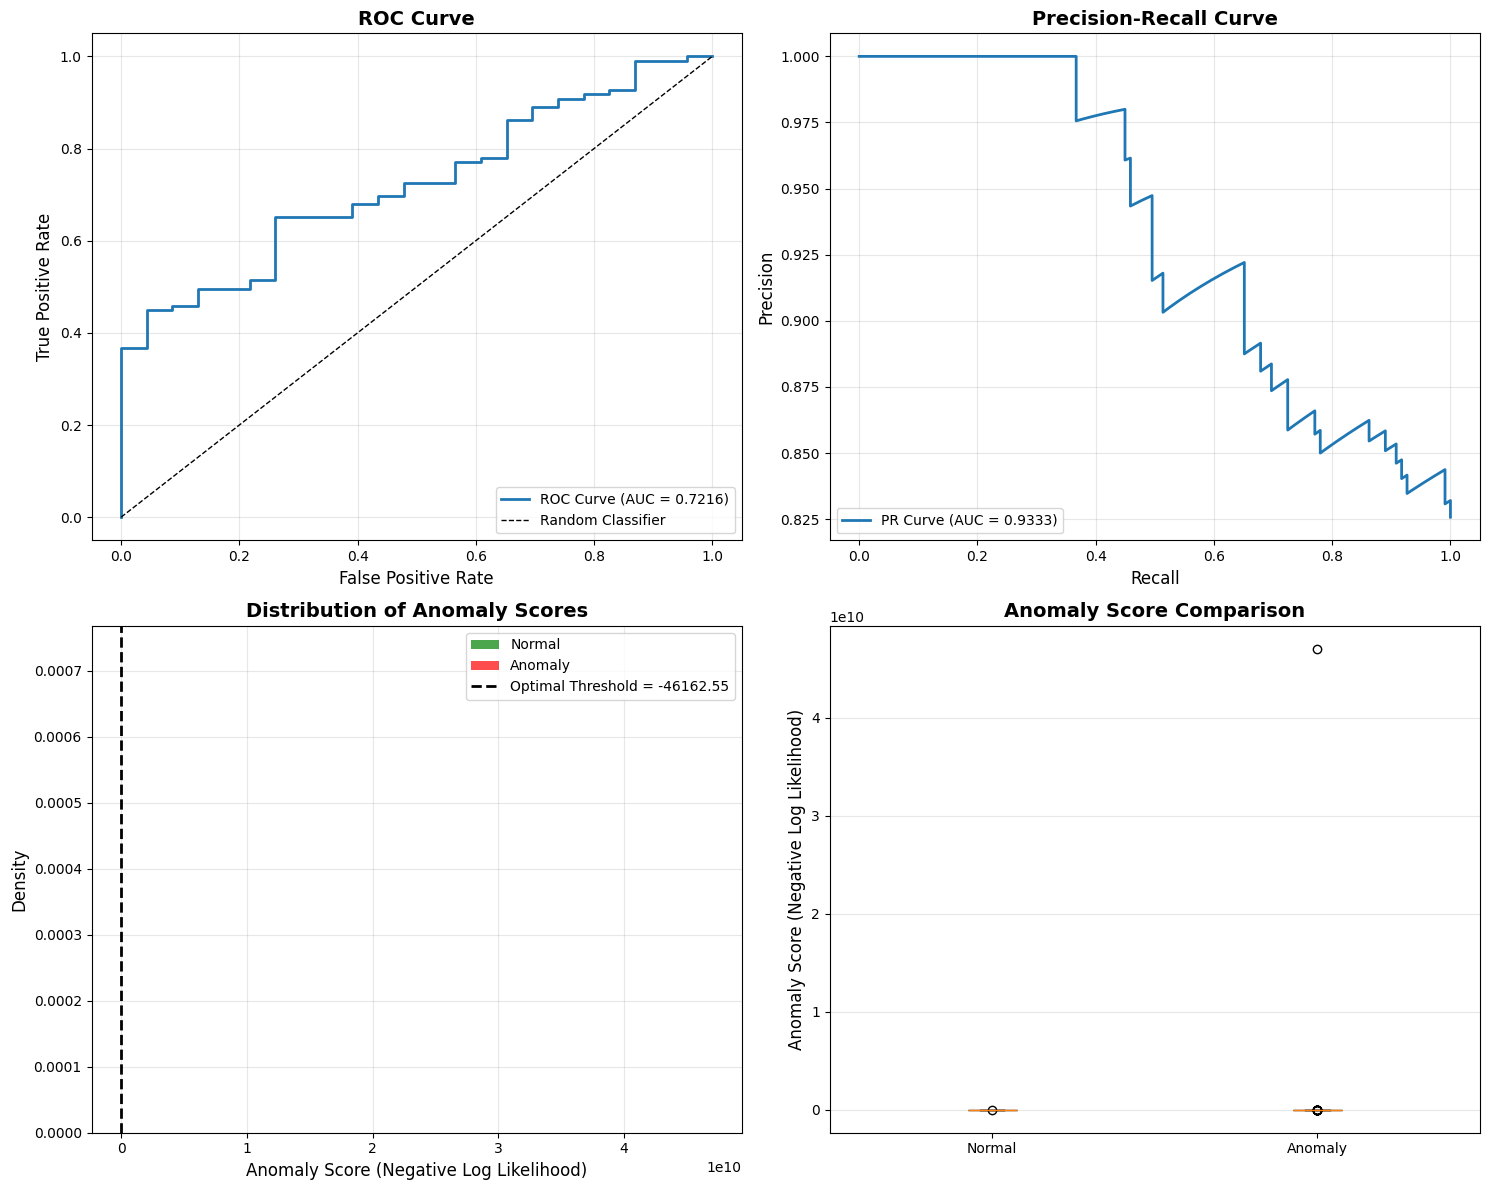

Anomaly detection results saved as 'anomaly_detection_results.png'


In [25]:
# Visualize results
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. ROC Curve
axes[0, 0].plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUC = {auroc:.4f})')
axes[0, 0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[0, 0].set_xlabel('False Positive Rate', fontsize=12)
axes[0, 0].set_ylabel('True Positive Rate', fontsize=12)
axes[0, 0].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[0, 0].legend(loc='lower right')
axes[0, 0].grid(alpha=0.3)

# 2. Precision-Recall Curve
axes[0, 1].plot(recall, precision, linewidth=2, label=f'PR Curve (AUC = {auprc:.4f})')
axes[0, 1].set_xlabel('Recall', fontsize=12)
axes[0, 1].set_ylabel('Precision', fontsize=12)
axes[0, 1].set_title('Precision-Recall Curve', fontsize=14, fontweight='bold')
axes[0, 1].legend(loc='lower left')
axes[0, 1].grid(alpha=0.3)

# 3. Anomaly Score Distribution
axes[1, 0].hist(anomaly_scores[true_labels == 0], bins=50, alpha=0.7, label='Normal', color='green', density=True)
axes[1, 0].hist(anomaly_scores[true_labels == 1], bins=50, alpha=0.7, label='Anomaly', color='red', density=True)
axes[1, 0].axvline(optimal_threshold, color='black', linestyle='--', linewidth=2, label=f'Optimal Threshold = {optimal_threshold:.2f}')
axes[1, 0].set_xlabel('Anomaly Score (Negative Log Likelihood)', fontsize=12)
axes[1, 0].set_ylabel('Density', fontsize=12)
axes[1, 0].set_title('Distribution of Anomaly Scores', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Box plot comparison
data_to_plot = [anomaly_scores[true_labels == 0], anomaly_scores[true_labels == 1]]
axes[1, 1].boxplot(data_to_plot, labels=['Normal', 'Anomaly'], patch_artist=True)
axes[1, 1].set_ylabel('Anomaly Score (Negative Log Likelihood)', fontsize=12)
axes[1, 1].set_title('Anomaly Score Comparison', fontsize=14, fontweight='bold')
axes[1, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('anomaly_detection_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("Anomaly detection results saved as 'anomaly_detection_results.png'")


### Question 4: VAE-based Anomaly Detection

**Question**: As you know, in VAE models, precise likelihood calculation is not possible; but it is interesting to know that these models are also used in anomaly detection. Explain how VAE models are used for anomaly detection.

**Answer:**

VAE (Variational Autoencoder) models cannot compute exact likelihood, but they can still be used for anomaly detection using **reconstruction error** as the anomaly score.

**How VAE-based Anomaly Detection Works:**

1. **Training Phase**:
   - Train the VAE **only on normal images**
   - The encoder learns to map normal images to a latent space
   - The decoder learns to reconstruct normal images from the latent representation
   - The model becomes good at encoding and reconstructing normal patterns

2. **Testing Phase**:
   - For each test image, pass it through the VAE:
     - **Encoder**: Maps image $x$ to latent representation $z$: $z = \text{encoder}(x)$
     - **Decoder**: Reconstructs image from latent: $\hat{x} = \text{decoder}(z)$
   - Compute **reconstruction error**: $\text{error} = ||x - \hat{x}||^2$ (or other distance metric)
   - Use reconstruction error as **anomaly score**

3. **Why This Works**:
   - **Normal images**: The VAE has seen similar patterns during training, so it can encode and reconstruct them well → **low reconstruction error** → **low anomaly score**
   - **Anomaly images**: The VAE has never seen these patterns, so:
     - The encoder may map them to an unfamiliar region of latent space
     - The decoder (trained only on normal images) tries to reconstruct them as "normal-looking" images
     - The reconstruction fails to capture the anomalous features → **high reconstruction error** → **high anomaly score**

**Key Difference from Normalizing Flow:**

| Method | Anomaly Score | Advantages | Disadvantages |
|--------|--------------|------------|---------------|
| **Normalizing Flow** | Negative Log Likelihood | Exact likelihood computation, theoretically sound | Requires invertible transformations |
| **VAE** | Reconstruction Error | Flexible architecture, good for complex data | No exact likelihood, reconstruction may not capture all anomalies |

**Intuition**:
- Normalizing Flow: "How likely is this sample under the learned normal distribution?"
- VAE: "How well can the model reconstruct this sample? If it's an anomaly, reconstruction will be poor."

Both approaches leverage the same principle: **models trained only on normal data will perform poorly on anomaly data**, but they measure this "poor performance" differently.


## Analysis and Discussion

### 1. Training vs Generation Time Comparison

The comparison above shows the time taken for training versus generating images.

### 2. Why Image Generation is Time-Consuming in Autoregressive Models

In autoregressive models like MAF, image generation is sequential and time-consuming because:

1. **Sequential Dependency**: Each pixel/dimension depends on all previous pixels/dimensions. To generate dimension $i$, we need to:
   - First generate dimensions $1, 2, ..., i-1$
   - Pass all previous dimensions through the MADE network
   - Compute the parameters (mean and scale) for dimension $i$
   - Sample dimension $i$ from the conditional distribution

2. **Forward Passes per Dimension**: For an image of size $128 \times 128 \times 3 = 49,152$ dimensions, we need to perform 49,152 forward passes through the MADE network (one for each dimension).

3. **No Parallelization**: Unlike training (where we can process batches in parallel), generation must be sequential due to the autoregressive property.

4. **Multiple Blocks**: With 7 MAF blocks, each dimension requires 7 sequential inverse transformations, further increasing computation time.

**Time Complexity**:
- Training: $O(N \times B \times D)$ where $N$ is number of samples, $B$ is batch size, $D$ is input dimension (can be parallelized)
- Generation: $O(D \times B \times D)$ where each of $D$ dimensions requires a forward pass through the network (sequential, cannot be parallelized)

### 3. MAF vs Inverse Autoregressive Flow (IAF)

**MAF (Masked Autoregressive Flow)**:
- **Training**: Fast - can process all dimensions in parallel during forward pass
- **Generation**: Slow - requires sequential generation, one dimension at a time
- **Use case**: Good for density estimation and training efficiency

**IAF (Inverse Autoregressive Flow)**:
- **Training**: Slower - requires sequential processing during training (inverse pass)
- **Generation**: Fast - can generate all dimensions in parallel
- **Use case**: Good when fast generation is more important than training speed

**Key Difference**:
- MAF: Fast training, slow generation (autoregressive in generation)
- IAF: Slow training, fast generation (autoregressive in training, parallel in generation)

The choice between MAF and IAF depends on whether you prioritize training speed (MAF) or generation speed (IAF).
